# Directional Implicit NN From LJ Data

This notebook generates target geometries with `LJFF`, optionally pretrains `NNPotentialFF` on target energies and force stationarity, then trains it with `DirectionalImplicitMultipleSystemOptimizer`. It is separated from the linesearch notebook because this optimizer does not use exact line minimization.


In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import DirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import LJFF, _random_lj_systems, _random_lj_ff_param
from geomatry.ff.NN import NNPotentialFF


In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [3]:
systemN = 40
N = 10
N_pairs = 30
max_Za = 1
fixed_atom_indices = [0, 1]

Ras, Zas, idx_is, idx_js = _random_lj_systems(systemN, N, N_pairs, max_Za, start_Za=1)
epsilon, sigma = _random_lj_ff_param(max_Za, epsilon_range=(0.7, 2.0), sigma_range=(0.9, 1.1))

target_ff = LJFF(max_Za)
target_ff.reset_parameters(epsilon, sigma)
params_star = copy.deepcopy(target_ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target epsilon', epsilon[1:, 1:].mean().item())
print('sample target sigma', sigma[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target epsilon 1.4020220675160804
sample target sigma 1.0341706290084085
sample min distances [0.9100425098438172, 0.7640350907618652, 0.9056789167476208]


In [4]:
# Use LJFF only to generate target optimized geometries.
target_optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, target_ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
Ra_star_list = target_optimizer.Ra_stars

from geomatry.opt_Energy_approximated.calculator import get_ase_atoms

with torch.no_grad():
    target_energies = torch.stack([
        target_ff.get_E(Ra_star, Za, *graph_builder(get_ase_atoms(Ra_star, Za))).detach()
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ]).float()

# Train the NN force field with directional implicit gradients.
nn_ff = NNPotentialFF(max_Za, hidden_dim=24)
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
params_0 = copy.deepcopy(nn_ff.state_dict())

print('target geometries', len(Ra_star_list))
print('NN parameter tensors', len(params_0))


target geometries 40
NN parameter tensors 18


In [5]:
from tqdm.auto import tqdm

def sample_pretrain_batch(batch_size):
    batch_size = min(batch_size, len(Ra_star_list))
    return torch.randperm(len(Ra_star_list))[:batch_size].tolist()

def predict_target_geometry_energies(ff, batch_indices):
    return torch.stack([
        ff.get_E(Ra_star_list[i].float(), Zas[i].long(), *graph_builders[i](get_ase_atoms(Ra_star_list[i], Zas[i])))
        for i in batch_indices
    ])

def force_square_loss_at_target_geometries(ff, batch_indices):
    force_terms = []
    for i in batch_indices:
        Ra_eval = Ra_star_list[i].detach().float().requires_grad_(True)
        E = ff.get_E(Ra_eval, Zas[i].long(), *graph_builders[i](get_ase_atoms(Ra_eval.detach(), Zas[i])))
        Fa = ff.get_Fa(E, Ra_eval)
        if fixed_atom_indices is not None:
            Fa = Fa.clone()
            Fa[fixed_atom_indices, :] = 0
        force_terms.append(torch.mean(Fa ** 2))
    return torch.stack(force_terms).mean()

def long_range_force_square_loss(ff, R_far_value):
    if not hasattr(ff, 'nets'):
        return torch.tensor(0.0)

    first_param = next(ff.parameters())
    loss_terms = []
    for net in ff.nets.values():
        for i in range(10):
            R_far = torch.tensor(
                [R_far_value+i],
                device=first_param.device,
                dtype=first_param.dtype,
                requires_grad=True,
            )
            E_far = net(R_far).sum()
            dE_dR = torch.autograd.grad(
                E_far,
                R_far,
                create_graph=True,
                retain_graph=True,
            )[0]
            loss_terms.append(torch.mean(dE_dR ** 2))
    return torch.stack(loss_terms).mean()

pretrain_optimizer = torch.optim.Adam(nn_ff.parameters(), lr=1e-3, weight_decay=1e-6)
pretrain_epochs = 1001
pretrain_print_period = 100
pretrain_batch_size = 8
force_loss_weight = 1.0
longRange = True
longRange_weight = 1.0
R_far_value = 10.0
pbar = tqdm(range(pretrain_epochs), desc='energy+force+longrange pretrain')
for epoch in pbar:
    batch_indices = sample_pretrain_batch(pretrain_batch_size)
    batch_target_energies = target_energies[batch_indices]

    pretrain_optimizer.zero_grad()
    y_pred = predict_target_geometry_energies(nn_ff, batch_indices)
    energy_loss = torch.mean((y_pred - batch_target_energies) ** 2)
    force_loss = force_square_loss_at_target_geometries(nn_ff, batch_indices)
    #longRange_loss = long_range_force_square_loss(nn_ff, R_far_value) if longRange else torch.tensor(0.0)
    loss = energy_loss + force_loss_weight * force_loss 
    #+ longRange_weight * longRange_loss
    loss.backward()
    pretrain_optimizer.step()

    errors = predict_target_geometry_energies(nn_ff, batch_indices).detach() - batch_target_energies
    rmse = torch.sqrt(torch.mean(errors ** 2)).item()
    mae = torch.mean(torch.abs(errors)).item()
    force_rmse = torch.sqrt(force_square_loss_at_target_geometries(nn_ff, batch_indices).detach()).item()
    pbar.set_postfix(
        batch=pretrain_batch_size,
        loss=f'{loss.item():.6e}',
        energy=f'{energy_loss.item():.6e}',
        force=f'{force_loss.item():.6e}',
        #longRange=f'{longRange_loss.item():.6e}',
        rmse=f'{rmse:.6f}',
        force_rmse=f'{force_rmse:.6f}',
    )

    if epoch % pretrain_print_period == 0 or epoch == pretrain_epochs - 1:
        tqdm.write(
            f'Pretrain {epoch}, batch={pretrain_batch_size}, loss={loss.item():.6e}, '
            f'energy_loss={energy_loss.item():.6e},'
            f'force_loss={force_loss.item():.6e},'
            #f'longRange_loss={longRange_loss.item():.6e},'
            f'rmse={rmse:.6f}, mae={mae:.6f},'
            f'force_rmse={force_rmse:.6f}'
        )

params_pretrained = copy.deepcopy(nn_ff.state_dict())
print('energy+force+longrange pretrain complete')


energy+force+longrange pretrain:   0%|          | 0/1001 [00:00<?, ?it/s]

Pretrain 0, batch=8, loss=1.065563e+04, energy_loss=1.064312e+04,force_loss=1.251164e+01,rmse=97.515374, mae=97.353711,force_rmse=3.278504
Pretrain 100, batch=8, loss=2.799317e+01, energy_loss=2.630812e+01,force_loss=1.685054e+00,rmse=5.038495, mae=3.560648,force_rmse=1.289027
Pretrain 200, batch=8, loss=2.054010e+01, energy_loss=1.927477e+01,force_loss=1.265330e+00,rmse=4.434432, mae=4.112191,force_rmse=1.117949
Pretrain 300, batch=8, loss=3.327200e+01, energy_loss=3.235774e+01,force_loss=9.142592e-01,rmse=5.702016, mae=5.416271,force_rmse=0.953595
Pretrain 400, batch=8, loss=4.940791e+01, energy_loss=4.875704e+01,force_loss=6.508725e-01,rmse=6.984563, mae=5.534543,force_rmse=0.807441
Pretrain 500, batch=8, loss=8.191761e+01, energy_loss=8.148578e+01,force_loss=4.318304e-01,rmse=8.923745, mae=7.930619,force_rmse=0.641033
Pretrain 600, batch=8, loss=9.624287e+01, energy_loss=9.608378e+01,force_loss=1.590891e-01,rmse=9.783226, mae=8.268243,force_rmse=0.384113
Pretrain 700, batch=8, loss

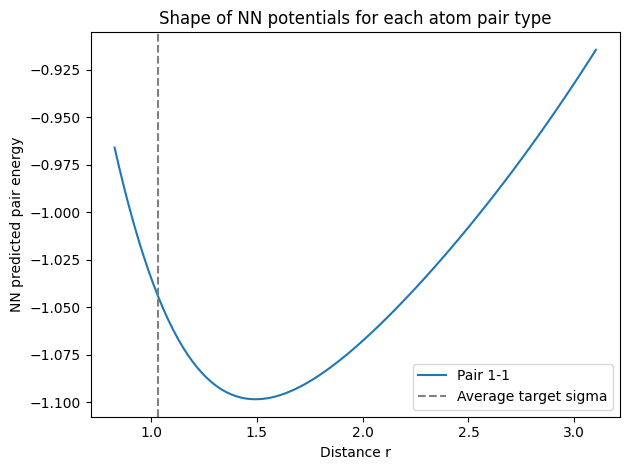

In [6]:

r_vals = torch.linspace(sigma[1:, 1:].mean().item()*0.8, sigma[1:, 1:].mean().item()*3, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.axvline(x=sigma[1:, 1:].mean().item(), color='gray', linestyle='--', label='Average target sigma')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()



  0%|          | 0/4001 [00:00<?, ?it/s, total_scale=1.132693e+00]

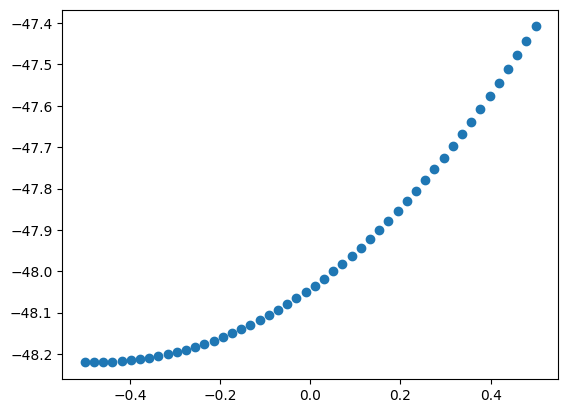

  0%|          | 2/4001 [00:00<16:11,  4.12it/s, total_scale=2.575165e+00]

deviation tensor(-0.4374, dtype=torch.float64, grad_fn=<DivBackward0>)
1.7829655069467105
Fratio 0.08628585696438604
Iteration 0, total_scale: 1.132693e+00


 25%|██▍       | 1000/4001 [02:50<08:29,  5.89it/s, total_scale=3.464670e-01]

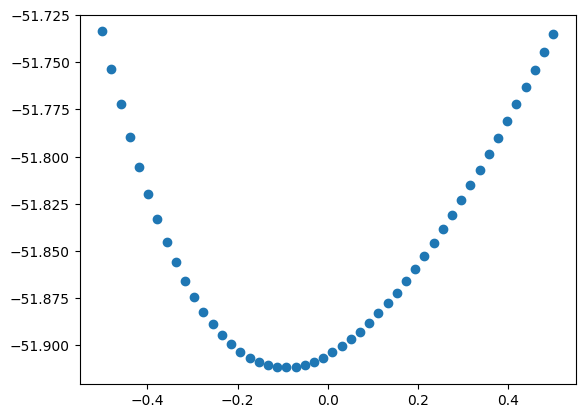

 25%|██▌       | 1002/4001 [02:51<10:39,  4.69it/s, total_scale=2.654200e-01]

deviation tensor(-0.0935, dtype=torch.float64, grad_fn=<DivBackward0>)
1.4231468031654078
Fratio 0.015887235143795867
Iteration 1000, total_scale: 3.464670e-01


 50%|████▉     | 2000/4001 [05:48<06:27,  5.16it/s, total_scale=2.064981e-01]

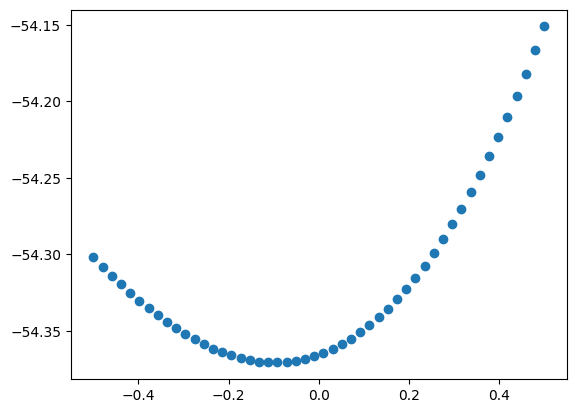

 50%|█████     | 2001/4001 [05:48<08:22,  3.98it/s, total_scale=2.064981e-01]

deviation tensor(-0.0957, dtype=torch.float64, grad_fn=<DivBackward0>)
1.102739175423449
Fratio 0.016275458834435107
Iteration 2000, total_scale: 2.064981e-01


 75%|███████▍  | 3000/4001 [08:52<02:51,  5.83it/s, total_scale=1.416017e-01]

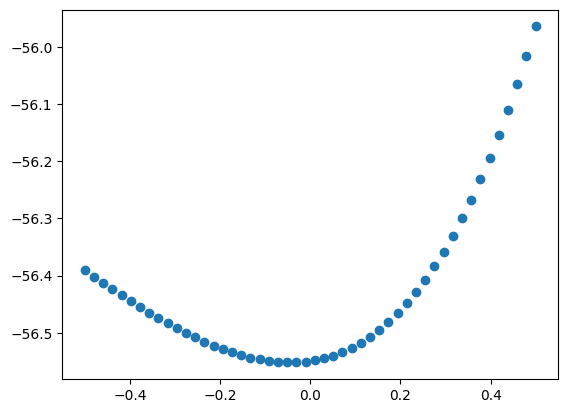

 75%|███████▌  | 3002/4001 [08:52<03:35,  4.64it/s, total_scale=1.331215e-01]

deviation tensor(-0.0374, dtype=torch.float64, grad_fn=<DivBackward0>)
3.056644231126966
Fratio 0.143314249139471
Iteration 3000, total_scale: 1.416017e-01


100%|█████████▉| 4000/4001 [11:46<00:00,  5.75it/s, total_scale=1.150605e-01]

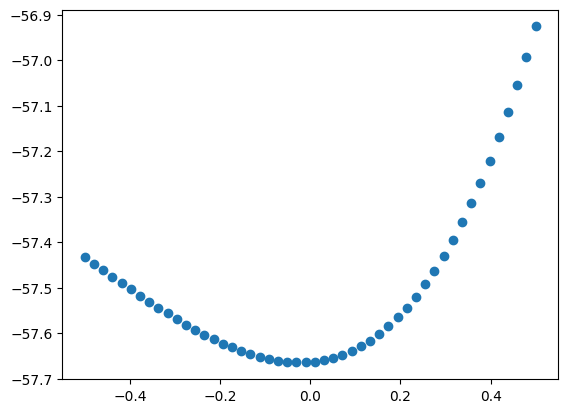

100%|██████████| 4001/4001 [11:46<00:00,  5.66it/s, total_scale=1.150605e-01]

deviation tensor(-0.0205, dtype=torch.float64, grad_fn=<DivBackward0>)
3.952491369479564
Fratio 0.10156471238357949
Iteration 4000, total_scale: 1.150605e-01
optimization complete


In [7]:
params_0 = copy.deepcopy(nn_ff.state_dict())
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
new_params = optimizer.optimize(params_0, lr=1e-3, epoch=4001, print_period=1000, e_size=0.2, eN=9, sg=2, longRange=False, R_far_value=5.0)
print('optimization complete')


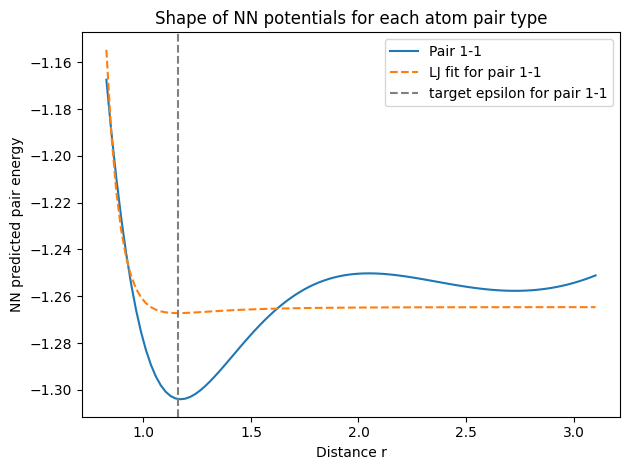

In [8]:

nn_ff.load_state_dict(new_params)

r_vals = torch.linspace(sigma[1:, 1:].mean().item()*0.8, sigma[1:, 1:].mean().item()*3, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
        epsilonij = target_ff.epsilon[i, j].item()
        sigma_ij = target_ff.sigma[i, j].item()

        inv_r = sigma_ij / (r_vals.numpy() + 1e-6)
        inv_r6 = inv_r ** 6
        inv_r12 = inv_r6 ** 2
        y = (4 * (epsilonij ** 2) * (inv_r12 - inv_r6)) / 2

        p = np.polyfit(y, energies, deg=1)
        plt.plot(r_vals.numpy(), p[0]*y + p[1], label=f'LJ fit for pair {i}-{j}', linestyle='--')

plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.axvline(sigma[i, j].item()*(2**(1/6)), color='gray', linestyle='--', label=f'target epsilon for pair {i}-{j}')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()


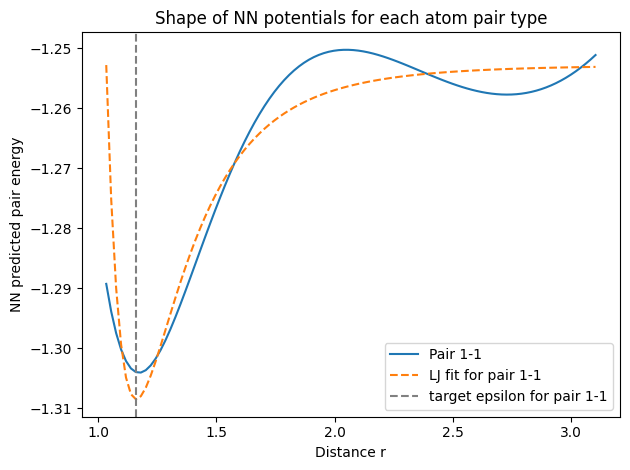

In [9]:

nn_ff.load_state_dict(new_params)

r_vals = torch.linspace(sigma[1:, 1:].mean().item()*1, sigma[1:, 1:].mean().item()*3, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
        epsilonij = target_ff.epsilon[i, j].item()
        sigma_ij = target_ff.sigma[i, j].item()

        inv_r = sigma_ij / (r_vals.numpy() + 1e-6)
        inv_r6 = inv_r ** 6
        inv_r12 = inv_r6 ** 2
        y = (4 * (epsilonij ** 2) * (inv_r12 - inv_r6)) / 2

        p = np.polyfit(y, energies, deg=1)
        plt.plot(r_vals.numpy(), p[0]*y + p[1], label=f'LJ fit for pair {i}-{j}', linestyle='--')

plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.axvline(sigma[i, j].item()*(2**(1/6)), color='gray', linestyle='--', label=f'target epsilon for pair {i}-{j}')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()


In [10]:
#The shape might not match due to long range part shape
#To make the same geometry with sum of potentials, short range should have different shape if long range is wrong
#However, we can't give appropriate penalty to long range side
#Problem is arbitrary resized potential gives same geometry.